**Student Name:** Shelia Howard  
**Course:** DSC680-T302 Applied Data Science (2271-1)  
**Assignment:** Term Project 2 - Milestone 3  
**Due Date:** 11/22/2026   
**Dataset(s):** UCI Bike Sharing, original `hour.csv` embedded below ([source](https://doi.org/10.24432/C5W894)).

---

# Bike Demand Forecasting for Operational Planning

I examined systemwide recorded Capital Bikeshare rentals to help managers identify when to review operating reserves. Recorded rentals reflect realized use and cannot measure unmet demand or station availability.

- **RQ1.** Does adding observed weather lower held-out mean absolute error for each algorithm compared with its calendar-only version? I expected a reduction.
- **RQ2.** When the calendar model selected on validation underestimates rentals, which hours, day types, and recorded weather groups have the largest mean shortfalls?

I audited the source file, evaluated the calendar and observed-weather models, measured underprediction, and exported figures and tables.

## Environment

Run all cells in a Python 3 Jupyter kernel with pandas, NumPy, scikit-learn (1.2 or newer), and Matplotlib installed. The first code cell reports the actual versions. The embedded source supports offline execution. Figures and tables are written to `outputs/`.


In [1]:
# Record versions and fix the seed for reproducibility.
import io, base64, hashlib, json, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)
print({'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__,'matplotlib':plt.matplotlib.__version__})
SEED=680

{'python': '3.11.16', 'pandas': '3.0.6', 'numpy': '2.4.6', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}


The setup records the runtime and fixes the random seed so that forest fitting and bootstrap sampling can be reproduced.

## Source verification and preparation

I used the UCI Bike Sharing archive retrieved on November 7, 2026 (Fanaee-T, 2013, CC BY 4.0). I decoded the embedded `hour.csv` and checked its SHA-256 against the stored digest to detect accidental byte changes. The digest verifies file identity. The repository documentation establishes provenance, and I did not independently audit the original measurements.

I combined date and hour into a timestamp so I could sort the records and identify absent hours. Checking missing cells alone would miss whole hours with no row. I kept all records and exported the gaps because filling them with zero would assume no rentals occurred. I checked key uniqueness, valid ranges, and the rental total identity. I used the published normalized weather measurements because the source descriptions differ on temperature scaling. I performed no joins or imputations. The hourly file contained the outcome and predictor fields needed for both research questions, so a join was unnecessary.

[UCI source archive](https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip)

In [2]:
# Verify the original bytes before interpreting the file.
raw=base64.b64decode('...')
assert hashlib.sha256(raw).hexdigest()=='e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f'
df=pd.read_csv(io.BytesIO(raw))


The source is decoded and its hash checked before loading, which detects accidental changes to the embedded data.

In [3]:
# Audit gaps separately from missing cells.
df['date']=pd.to_datetime(df.dteday)
df['timestamp']=df.date+pd.to_timedelta(df.hr,unit='h')
df=df.sort_values('timestamp').reset_index(drop=True)
assert df.isna().sum().sum()==0
assert not df.duplicated(['date','hr']).any()
assert (df.cnt==df.casual+df.registered).all()
for col,lo,hi in [('hr',0,23),('weekday',0,6),('mnth',1,12),('yr',0,1),('holiday',0,1),('workingday',0,1),('weathersit',1,4),('temp',0,1),('hum',0,1),('windspeed',0,1)]:
    assert df[col].between(lo,hi).all(),col
assert (df.cnt>=0).all()
expected=pd.date_range(df.timestamp.min(),df.timestamp.max(),freq='h')
missing=expected.difference(df.timestamp)
audit={'rows':len(df),'dates':df.date.nunique(),'missing_cells':0,'duplicate_keys':0,'expected_hours':len(expected),'absent_hours':len(missing),'sha256':hashlib.sha256(raw).hexdigest()}
print(audit)
pd.DataFrame({'absent_timestamp':missing}).to_csv(OUT/'absent_hours.csv',index=False)

{'rows': 17379, 'dates': 731, 'missing_cells': 0, 'duplicate_keys': 0, 'expected_hours': 17544, 'absent_hours': 165, 'sha256': 'e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f'}


The audit distinguishes missing cells from missing timestamps and verifies that the target equals the two rental components. Keeping the absent hours unfilled preserves the distinction between unknown and zero rentals.

## Chronological partitioning and model selection

I reserved the last 147 dates for final evaluation. I split the earlier 584 dates into three expanding validation folds because a random hourly split would mix earlier and later observations and could put hours from the same date on both sides. Each fold evaluates a later block against models fit on the earlier dates. Mean absolute error (MAE) measures average error in rentals per recorded hour. Root mean squared error (RMSE) gives larger misses more weight. I used MAE for selection and reported both on the final holdout (scikit-learn developers, n.d.-a).

I used the historical hour-by-weekday mean as the operational baseline. I compared Ridge, an additive model with a penalty that shrinks coefficients, and random forest, which can learn interactions such as different commute peaks on working days and weekends. I considered boosting and models that use lagged counts. I limited the comparison to two algorithms and two settings per algorithm so I could compare weather and calendar versions on the same date blocks without requiring recent observed counts (scikit-learn developers, n.d.-b, n.d.-c).

I encoded calendar codes and weather category as separate indicators because numeric distance between codes is not meaningful. I scaled normalized numeric weather fields within the pipeline so Ridge applies its penalty on comparable scales. I fit preprocessing within each training fold to keep validation observations out of the fitted transformations. I excluded `casual` and `registered` because they sum to the target, `instant` because it is an identifier, and `season` and `atemp` because month and temperature already represent those inputs.

I chose each configuration by its unweighted mean validation MAE, then used the same criterion to choose the calendar model for RQ2 before examining the test results. I clipped negative model predictions at zero because rentals cannot be negative. I kept fractional estimates for error calculations.

In [4]:
# Choose settings on earlier folds before scoring the holdout.
dates=np.sort(df.date.unique()); cut=int(len(dates)*.8)
train=df[df.date.isin(dates[:cut])].copy(); test=df[df.date.isin(dates[cut:])].copy()
splits=[]
for a,b in TimeSeriesSplit(n_splits=3).split(dates[:cut]):
    splits.append((train[train.date.isin(dates[a])],train[train.date.isin(dates[b])]))
split_table=pd.DataFrame([{'fold':i+1,'train_end':a.date.max(),'validation_start':b.date.min(),'validation_end':b.date.max(),'train_n':len(a),'validation_n':len(b)} for i,(a,b) in enumerate(splits)])
display(split_table); print('Final train/test:',len(train),len(test),train.date.min(),train.date.max(),test.date.min(),test.date.max())


cats=['hr','weekday','mnth','workingday','holiday','yr']
def model(algorithm,weather,param):
    c=cats+(['weathersit'] if weather else [])
    num=['temp','hum','windspeed'] if weather else []
    prep=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),c),('num',StandardScaler(),num)])
    est=Ridge(alpha=param) if algorithm=='Ridge' else RandomForestRegressor(n_estimators=120,min_samples_leaf=param,random_state=SEED,n_jobs=2)
    return Pipeline([('prep',prep),('model',est)])

def pred(m, x):
    return np.maximum(0, m.predict(x))

cv = []
chosen = {}

for alg, params in [('Ridge', [1, 100]), ('Forest', [2, 10])]:
    for weather in [False, True]:
        for param in params:
            for i, (a, b) in enumerate(splits):
                m = model(alg, weather, param).fit(a, a.cnt)
                cv.append({
                    'algorithm': alg,
                    'weather': weather,
                    'parameter': param,
                    'fold': i + 1,
                    'MAE': mean_absolute_error(b.cnt, pred(m, b)),
                })
cv=pd.DataFrame(cv); summary=cv.groupby(['algorithm','weather','parameter'],as_index=False).MAE.mean()
for (alg,w),g in summary.groupby(['algorithm','weather']): chosen[(alg,bool(w))]=g.loc[g.MAE.idxmin(),'parameter']
calendar_scores={alg:float(summary.query('algorithm==@alg and weather==False and parameter==@par').MAE.iloc[0]) for (alg,w),par in chosen.items() if not w}
selected=min(calendar_scores,key=calendar_scores.get)

# Show mean validation MAE for all tested settings.
display(summary)

# Show each fold for the two calendar configurations chosen by validation.
calendar_fold_mae = cv.loc[
    ~cv['weather'] & (
        ((cv['algorithm'] == 'Ridge') & (cv['parameter'] == chosen[('Ridge', False)]))
        | ((cv['algorithm'] == 'Forest') & (cv['parameter'] == chosen[('Forest', False)]))
    )
].pivot(index='fold', columns='algorithm', values='MAE')

calendar_fold_mae = calendar_fold_mae.rename(columns={
    'Ridge': f"Calendar ridge (alpha={chosen[('Ridge', False)]})",
    'Forest': f"Calendar random forest (min_samples_leaf={chosen[('Forest', False)]})",
})
calendar_fold_mae = calendar_fold_mae[
    [
        f"Calendar ridge (alpha={chosen[('Ridge', False)]})",
        f"Calendar random forest (min_samples_leaf={chosen[('Forest', False)]})",
    ]
].rename_axis(index='Validation fold', columns=None)

print('Calendar model validation MAE (rentals per hour)')
display(calendar_fold_mae.round(2))

print('Selected calendar:', selected)

metrics=[]; predictions={}
means=train.groupby(['hr','weekday']).cnt.mean()
overall_mean = train.cnt.mean()
baseline=np.array([means.get((h,w),overall_mean) for h,w in zip(test.hr,test.weekday)])
predictions['Baseline']=baseline
for (alg,w),par in chosen.items():
 m=model(alg,w,par).fit(train,train.cnt)
 predictions[alg+(' + weather' if w else ' calendar')]=pred(m,test)
for label,yhat in predictions.items():
 metrics.append({'model':label,'MAE':mean_absolute_error(test.cnt,yhat),'RMSE':np.sqrt(mean_squared_error(test.cnt,yhat))})
metrics=pd.DataFrame(metrics); display(metrics)
cv.to_csv(OUT/'validation_results.csv',index=False); metrics.to_csv(OUT/'test_metrics.csv',index=False)

,fold,train_end,validation_start,validation_end,train_n,validation_n
0,1,2011-05-26,2011-05-27,2011-10-19,3410,3487
1,2,2011-10-19,2011-10-20,2012-03-13,6897,3492
2,3,2012-03-13,2012-03-14,2012-08-06,10389,3502


Final train/test: 13891 3488 2011-01-01 00:00:00 2012-08-06 00:00:00 2012-08-07 00:00:00 2012-12-31 00:00:00


,algorithm,weather,parameter,MAE
0,Forest,False,2,91.568640
1,Forest,False,10,94.357348
2,Forest,True,2,73.109378
3,Forest,True,10,82.320302
4,Ridge,False,1,91.349480
5,Ridge,False,100,98.952430
6,Ridge,True,1,81.480231
7,Ridge,True,100,89.450143


Calendar model validation MAE (rentals per hour)


,Calendar ridge (alpha=1),Calendar random forest (min_samples_leaf=2)
Validation fold,,
1,91.63,112.33
2,69.50,71.15
3,112.92,91.23


Selected calendar: Ridge


,model,MAE,RMSE
0,Baseline,101.333440,145.507174
1,Forest calendar,67.196666,109.589963
2,Forest + weather,55.278840,83.181123
3,Ridge calendar,106.065285,142.501187
4,Ridge + weather,100.293407,135.590035


I used date-based folds to keep training observations earlier than validation observations. The pipeline fitted its encoders and scaler within each fold. Calendar ridge had the lowest mean validation MAE across the three folds, at **91.35** rentals per hour compared with **91.57** for calendar random forest. In the most recent validation fold, random forest performed better, with an MAE of **91.23** compared with **112.92** for ridge. The ranking varied across validation periods. I retained ridge for RQ2 because the selection rule used the mean across all three folds.

## Paired weather comparison and uncertainty

I subtracted each weather model’s absolute error from its calendar counterpart’s error for the same recorded hour. Positive values favor weather. I drew 2,000 bootstrap samples of entire test dates to retain within-day dependence and computed the hourly mean difference for each sample. Sampling hours independently would break that dependence. The percentile intervals reflect uncertainty for these fitted models and this test period. Dependence across adjacent days could make the intervals too narrow, and the intervals omit model training uncertainty.

In [5]:
# Resample dates to preserve dependence among hours on the same day.
rng=np.random.default_rng(SEED); comparisons=[]
for alg in ['Ridge','Forest']:
 delta=np.abs(test.cnt.to_numpy()-predictions[alg+' calendar'])-np.abs(test.cnt.to_numpy()-predictions[alg+' + weather'])
 blocks=pd.DataFrame({'date':test.date,'delta':delta}).groupby('date').delta.agg(['sum','count'])
 idx=rng.integers(0,len(blocks),size=(2000,len(blocks)))
 boot=blocks['sum'].to_numpy()[idx].sum(axis=1)/blocks['count'].to_numpy()[idx].sum(axis=1)
 base=metrics.set_index('model').loc[alg+' calendar','MAE']
 comparisons.append({'algorithm':alg,'improvement':delta.mean(),'percent':100*delta.mean()/base,'lower':np.quantile(boot,.025),'upper':np.quantile(boot,.975)})
comparisons=pd.DataFrame(comparisons); display(comparisons)


,algorithm,improvement,percent,lower,upper
0,Ridge,5.771878,5.441816,3.744597,7.947138
1,Forest,11.917826,17.735740,5.053403,19.141379


The comparison pairs both predictions on each test hour and resamples whole dates. The resulting interval preserves within-day dependence and describes uncertainty for the fitted models.

## Shortfalls and busy periods

I used the validation-selected calendar model for RQ2. I defined a shortfall as actual rentals minus predicted rentals when that difference was positive. I divided the number of underpredicted hours by all recorded hours in each group to measure frequency separately. For groups with no underpredictions, the conditional mean is undefined. I grouped hours, day types, and weather separately because the largest group in each view does not establish a joint operating rule.

I defined busy hours using the pre-test 90th percentile, then applied that threshold to actual test counts. This measures performance on retrospectively identified busy hours and avoids using the test data to set the cutoff.

In [6]:
# Use a training-derived cutoff to evaluate realized busy hours.
res=test[['timestamp','date','hr','workingday','holiday','weathersit','cnt']].copy()
res['prediction']=predictions[selected+' calendar']; res['error']=res.cnt-res.prediction
res['under']=res.error>0
res['day_type']=np.where(res.workingday==1,'Working day',np.where(res.holiday==1,'Holiday','Weekend'))
weather_labels={1:'Clear / partly cloudy',2:'Mist / cloudy',3:'Light rain / snow',4:'Heavy precipitation'}
res['weather']=res.weathersit.map(weather_labels)
res['shortfall'] = res['error'].where(res['under'])

def groups(column):
    return res.groupby(column, as_index=False).agg(
        hours=('under', 'size'),
        under_hours=('under', 'sum'),
        under_share=('under', 'mean'),
        conditional_shortfall=('shortfall', 'mean'),
    )
group_tables={c:groups(c) for c in ['hr','day_type','weather']}
for c,t in group_tables.items():
 display(t); t.to_csv(OUT/('shortfalls_'+c+'.csv'),index=False)
threshold=float(train.cnt.quantile(.9)); busy=res.cnt>=threshold
busy_stats={'threshold':threshold,'n':int(busy.sum()),'MAE':float(np.abs(res.loc[busy,'error']).mean()),'under_share':float(res.loc[busy,'under'].mean()),'conditional_shortfall':float(res.loc[busy & res.under,'error'].mean())}
print('Busy-hour results:',busy_stats)
display(res.nlargest(10,'error')[['timestamp','cnt','prediction','error','weather']])
res.drop(columns='shortfall').to_csv(OUT/'test_predictions.csv',index=False)

,hr,hours,under_hours,under_share,conditional_shortfall
0,0,146,22,0.150685,33.909414
1,1,145,18,0.124138,21.499448
2,2,145,7,0.048276,21.209489
3,3,142,1,0.007042,9.142144
4,4,144,0,0.000000,NaN
5,5,145,0,0.000000,NaN
6,6,145,43,0.296552,15.797280
7,7,145,85,0.586207,164.195674
8,8,145,90,0.620690,291.579585
9,9,145,97,0.668966,61.774159


,day_type,hours,under_hours,under_share,conditional_shortfall
0,Holiday,119,32,0.268908,100.518864
1,Weekend,1008,346,0.343254,169.704354
2,Working day,2361,907,0.384159,131.018335


,weather,hours,under_hours,under_share,conditional_shortfall
0,Clear / partly cloudy,2168,866,0.399446,151.067226
1,Light rain / snow,238,42,0.176471,120.547376
2,Mist / cloudy,1082,377,0.348429,119.047036


Busy-hour results: {'threshold': 413.0, 'n': 730, 'MAE': 213.56002485920015, 'under_share': 0.9780821917808219, 'conditional_shortfall': 217.72161154320918}


,timestamp,cnt,prediction,error,weather
14773,2012-09-12 18:00:00,977,490.059732,486.940268,Clear / partly cloudy
14725,2012-09-10 18:00:00,968,489.902271,478.097729,Clear / partly cloudy
15031,2012-09-23 12:00:00,776,320.926255,455.073745,Clear / partly cloudy
15780,2012-10-24 17:00:00,963,509.264221,453.735779,Clear / partly cloudy
14964,2012-09-20 17:00:00,976,527.568940,448.431060,Clear / partly cloudy
14748,2012-09-11 17:00:00,970,524.928879,445.071121,Clear / partly cloudy
15084,2012-09-25 17:00:00,967,524.928879,442.071121,Clear / partly cloudy
15849,2012-10-27 14:00:00,750,309.763536,440.236464,Clear / partly cloudy
15848,2012-10-27 13:00:00,760,321.133399,438.866601,Clear / partly cloudy
16173,2012-11-11 15:00:00,724,285.161593,438.838407,Clear / partly cloudy


The grouped summaries report the size of misses separately from their frequency. The busy-hour cutoff is defined by training counts and then applied to held-out counts for evaluation.

## Illustrations and operational interpretation

I used training data in Figure 1 to show recurring usage patterns without using the holdout for that context. Figure 2 compares typical error and sensitivity to large misses on the same held-out hours. Figure 3 shows the first seven calendar days after the split so the display is anchored to a fixed date rule. Figures 4 and 5 show the size of misses for the validation-selected calendar model. The subgroup tables in Shortfalls and busy periods pair miss sizes with the number of recorded hours and underpredicted hours.

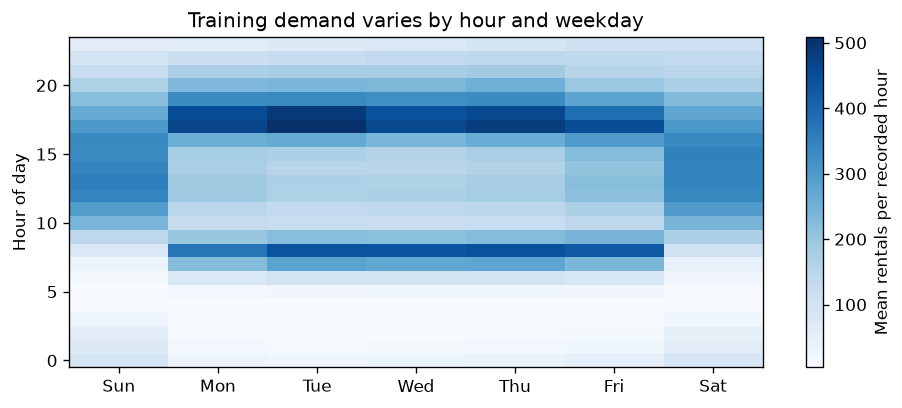

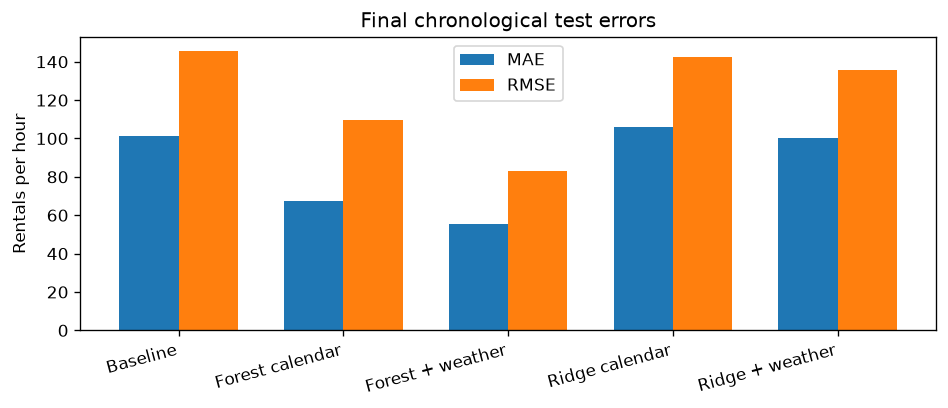

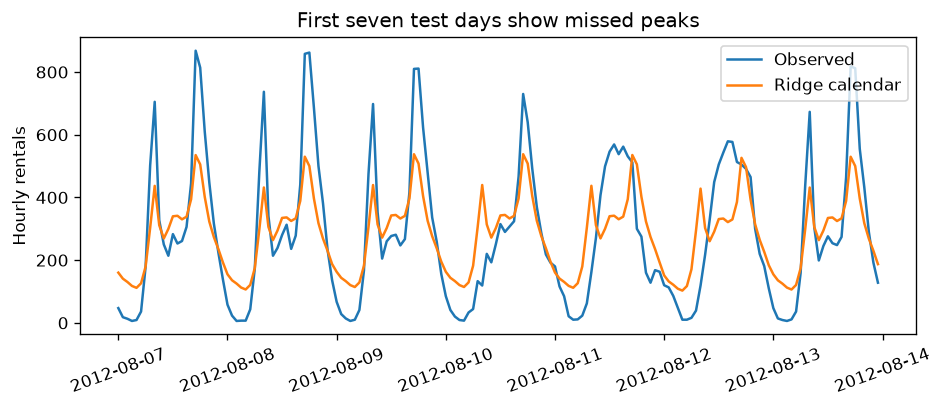

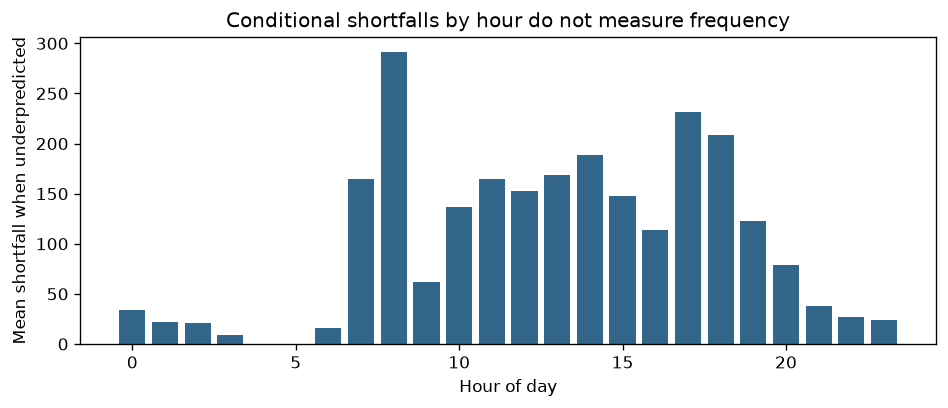

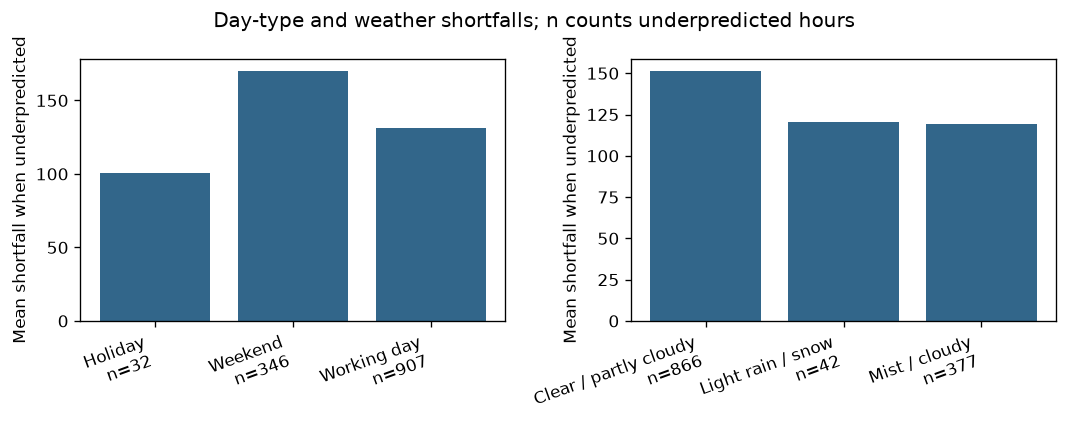

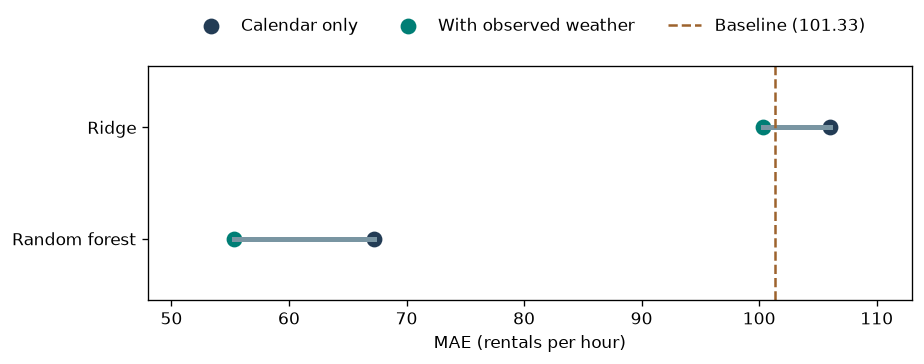

In [7]:
# Save figures and tables from the same predictions used in the report.
plt.rcParams.update({'figure.dpi':120,'font.size':10})
def save(name):
 plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight'); plt.show(); plt.close()
fig,ax=plt.subplots(figsize=(8,3.5)); heat=train.pivot_table(index='hr',columns='weekday',values='cnt',aggfunc='mean')
im=ax.imshow(heat,aspect='auto',origin='lower',cmap='Blues'); ax.set_xticks(range(7),['Sun','Mon','Tue','Wed','Thu','Fri','Sat']); ax.set_ylabel('Hour of day'); fig.colorbar(im,ax=ax,label='Mean rentals per recorded hour'); ax.set_title('Training demand varies by hour and weekday'); save('figure1')
fig,ax=plt.subplots(figsize=(8,3.5)); x=np.arange(len(metrics)); ax.bar(x-.18,metrics.MAE,.36,label='MAE'); ax.bar(x+.18,metrics.RMSE,.36,label='RMSE'); ax.set_xticks(x,metrics.model,rotation=15,ha='right'); ax.set_ylabel('Rentals per hour'); ax.legend(); ax.set_title('Final chronological test errors'); save('figure2')
fig,ax=plt.subplots(figsize=(8,3.5)); week=res[res.date<res.date.min()+pd.Timedelta(days=7)]; ax.plot(week.timestamp,week.cnt,label='Observed'); ax.plot(week.timestamp,week.prediction,label=selected+' calendar'); ax.set_ylabel('Hourly rentals'); ax.legend(); ax.tick_params(axis='x',rotation=20); ax.set_title('First seven test days show missed peaks'); save('figure3')
fig,ax=plt.subplots(figsize=(8,3.5)); g=group_tables['hr']; ax.bar(g.hr,g.conditional_shortfall,color='#32668a'); ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean shortfall when underpredicted'); ax.set_title('Conditional shortfalls by hour do not measure frequency'); save('figure4')
fig,axes=plt.subplots(1,2,figsize=(9,3.7))
for ax,c in zip(axes,['day_type','weather']):
 g=group_tables[c]; ax.bar(np.arange(len(g)),g.conditional_shortfall,color='#32668a'); ax.set_xticks(np.arange(len(g)),[str(v)+'\nn='+str(int(k)) for v,k in zip(g[c],g.under_hours)],rotation=20,ha='right'); ax.set_ylabel('Mean shortfall when underpredicted')
fig.suptitle('Day-type and weather shortfalls; n counts underpredicted hours'); save('figure5')
result={'audit':audit,'split_table':split_table.astype(str).to_dict('records'),'train_n':len(train),'test_n':len(test),'train_end':str(train.date.max().date()),'test_start':str(test.date.min().date()),'test_end':str(test.date.max().date()),'selected':selected,'cv':summary.to_dict('records'),'metrics':metrics.to_dict('records'),'comparisons':comparisons.to_dict('records'),'groups':{k:json.loads(v.to_json(orient='records', double_precision=15)) for k,v in group_tables.items()},'busy':busy_stats,'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__}}
(OUT/'results.json').write_text(json.dumps(result, indent=2, allow_nan=False))
# Export the two comparisons used in the presentation from the fitted results.
fig, ax = plt.subplots(figsize=(7.8, 3.3))
for y, alg in enumerate(['Ridge', 'Forest']):
    scores = metrics.set_index('model').MAE
    calendar = scores[alg + ' calendar']
    weather = scores[alg + ' + weather']
    ax.plot([weather, calendar], [y, y], color='#7995a2', lw=3)
    ax.scatter(calendar, y, color='#233c55', s=72, label='Calendar only' if y == 0 else None)
    ax.scatter(weather, y, color='#007e75', s=72, label='With observed weather' if y == 0 else None)
ax.axvline(scores['Baseline'], color='#9d632d', ls='--', label='Baseline (101.33)')
ax.set(yticks=[0, 1], yticklabels=['Ridge', 'Random forest'], xlabel='MAE (rentals per hour)', ylim=(-.55, 1.55), xlim=(48, 113))
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.27), ncol=3, frameon=False)
save('presentation_weather')


The figures expose patterns in training and compare held-out performance and miss severity. The exported tables and JSON support checking values in the paper and presentation.

## Findings and decisions
**RQ1:** I found that adding observed weather reduced ridge MAE from 106.07 to 100.29 rentals per hour (5.4%; approximate 95% day-bootstrap reduction interval 3.74–7.95). Forest MAE falls from 67.20 to 55.28 (17.7%; interval 5.05–19.14). Both support the weather hypothesis for this historical period, conditional on fitted models and observed weather.

**Model selection and held-out performance**

1. **Model selected for RQ2.** I selected calendar ridge before evaluating the holdout because it had the lowest mean validation MAE across the three folds: 91.35 rentals per hour versus 91.57 for calendar random forest. I used calendar ridge to answer RQ2 about underprediction.

2. **Lowest test MAE among calendar models.** On the holdout, calendar random forest had the lowest MAE among the calendar models at 67.20 rentals per hour. The hour-by-weekday baseline scored 101.33, and calendar ridge scored 106.07.

3. **Lowest test MAE overall.** Random forest with observed weather had the lowest holdout MAE of all evaluated approaches at 55.28 rentals per hour. It used weather measured during the hours being predicted. Evaluating it for day-ahead planning would require archived forecasts available at the planning cutoff.

**RQ2:** Ridge’s largest conditional hourly shortfall is at 08:00, 291.6 rentals (90/145 hours underpredicted, 62.1%). Weekend leads day types at 169.7 (346/1,008; 34.3%); clear/partly cloudy leads observed weather groups at 151.1 (866/2,168; 39.9%). These are separate, descriptive views, not a joint subgroup. At 04:00 and 05:00 there are no underpredictions, so conditional means are undefined, not zero. Severe weather is absent from the final test groups.

Busy hours use training threshold 413 rentals: 730 test hours meet it, MAE is 213.6, and 97.8% are underpredicted. The selected calendar ridge model frequently underestimated rentals during busy hours in the holdout. I interpreted the errors as evidence for reviewing busy periods. Estimating staffing or reserves requires workload, supply, and cost information.

**Source caveats:** I verified 17,379 hourly rows, versus 17,389 on the landing page. There are 165 absent timestamps and no missing cells. UCI’s current hourly temperature normalization description differs from the archive README, so normalized values are retained without physical-unit conversion. This preserves original measurements and avoids claiming a temperature scale that was not reconciled. Source credibility rests on documented UCI provenance, not an independent audit of original collection.

## Ethical assessment

**Identify.** I identified risks from unequal access, planning errors, gaps in coverage, overstatement of forecast accuracy, and potential linkage to rider information. The public dataset contains aggregate recorded rentals and does not reveal who could not find a bike.

**Assess.** I rated unequal access and forecast overstatement as moderate likelihood and high impact. I rated planning errors and coverage bias as moderate on both dimensions, and rider linkage as low likelihood with moderate impact. These ratings reflect qualitative judgments.

**Mitigate.** I retained all recorded hours, documented feature exclusions, exported missing timestamps and group denominators, and labeled weather as historical observations. I credited the dataset under CC BY 4.0 and used no rider-level records or external joins. For operational use, I recommend station-level access checks before any geographic service decision and a supervised trial using forecasts available at a fixed lead time. Adding sources would require reviewing their permissions and applicable privacy and data-use obligations.

## References

Fanaee-T, H. (2013). *Bike sharing* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

scikit-learn developers. (n.d.-a). *Cross-validation: Evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html

scikit-learn developers. (n.d.-b). *RandomForestRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

scikit-learn developers. (n.d.-c). *Ridge*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

## Conclusion

The historical test supports adding observed weather for both algorithms. Ridge was selected in advance for the shortfall analysis and showed its largest conditional hourly miss at 8:00 a.m. Its test MAE exceeded the operational baseline, and underprediction was frequent during busy hours. Before operational use, the next evaluation should compare the baseline and both models on recent chronological data, with archived forecasts available at the planning lead time. A supervised pilot can then assess whether the estimates help managers review staffing workload and fleet reserves.